# 👟 Shoe Type Classification using Deep Learning
**Model:** MobileNetV2 (transfer learning) • **Framework:** TensorFlow / Keras • **Runs on CPU**

**Classes:** Sneakers, Boots, Sandals, Heels, Loafers

### How to use this notebook
Run the cells **one by one from top to bottom** (click a cell, press `Shift + Enter`).
Do not skip cells. Training takes roughly 10–20 minutes on a normal laptop CPU.

**Steps:** 1) Imports → 2) Settings → 3) Get dataset → 4) Split train/validation → 5) Load data → 6) Build model → 7) Train → 8) Fine-tune → 9) Evaluate → 10) Save → 11) Test

## Step 1: Import libraries

In [9]:
import os, json, random, shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)
print("GPU found:", tf.config.list_physical_devices('GPU'), "(not needed - CPU is fine)")

TensorFlow version: 2.21.0
GPU found: [] (not needed - CPU is fine)


## Step 2: Settings
Folder paths and training settings. Run this notebook from inside the `ShoeTypeClassification` folder.

In [7]:
PROJECT_DIR = Path.cwd()
RAW_DIR   = PROJECT_DIR / "raw_images"            # downloaded / original images
TRAIN_DIR = PROJECT_DIR / "dataset" / "train"
VAL_DIR   = PROJECT_DIR / "dataset" / "validation"
MODEL_DIR = PROJECT_DIR / "model"
MODEL_DIR.mkdir(exist_ok=True)

CLASS_NAMES_LIST = ["sneakers", "boots", "sandals", "heels", "loafers"]

IMG_SIZE   = (224, 224)   # MobileNetV2 input size
BATCH_SIZE = 32
EPOCHS     = 10           # first training stage
FINE_TUNE_EPOCHS = 5      # second (optional) stage
SEED = 42

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("Project folder:", PROJECT_DIR)

Project folder: C:\Users\MOULIKA\Downloads\ShoeTypeClassification\ShoeTypeClassification


## Step 3: Get the dataset (easiest way)
**Option A (automatic, recommended):** the cell below downloads about 150 images per class from the internet (Bing image search). No account needed, but you need internet. Takes about 5–10 minutes.

**Option B (manual):** download any shoe dataset (for example from Kaggle: search *"shoe classification dataset"*) and copy the pictures into
`raw_images/sneakers`, `raw_images/boots`, `raw_images/sandals`, `raw_images/heels`, `raw_images/loafers`.
Then set `DOWNLOAD_IMAGES = False` below.

> Tip: more images and cleaner images = better accuracy. After downloading, open `raw_images` and delete any wrong pictures (for example a boot inside the sandals folder).

In [12]:
DOWNLOAD_IMAGES = True      # set to False if you copied images manually (Option B)
IMAGES_PER_CLASS = 150

SEARCH_TERMS = {
    "sneakers": "sneakers shoe white background",
    "boots":    "ankle boots shoe white background",
    "sandals":  "sandals footwear white background",
    "heels":    "high heels shoe white background",
    "loafers":  "men loafers shoe white background",
}

if DOWNLOAD_IMAGES:
    from icrawler.builtin import BingImageCrawler
    for cls, query in SEARCH_TERMS.items():
        out = RAW_DIR / cls
        out.mkdir(parents=True, exist_ok=True)
        print(f"Downloading '{cls}' images ...")
        crawler = BingImageCrawler(storage={"root_dir": str(out)}, log_level=40)
        crawler.crawl(keyword=query, max_num=IMAGES_PER_CLASS)
    print("Download finished!")
else:
    print("Skipping download. Using images already inside raw_images/")

2026-10-03 20:07:37,119 - ERROR - downloader - Exception caught when downloading file https://thumbs.dreamstime.com/z/shoes-isolated-white-background-shoes-white-background-illustration-shoe-shop-273641446.jpg, error: HTTPSConnectionPool(host='thumbs.dreamstime.com', port=443): Read timed out. (read timeout=5), remaining retry times: 2
2026-10-03 20:07:42,368 - ERROR - downloader - Exception caught when downloading file https://thumbs.dreamstime.com/z/shoes-isolated-white-background-shoes-white-background-illustration-shoe-shop-273641446.jpg, error: HTTPSConnectionPool(host='thumbs.dreamstime.com', port=443): Read timed out. (read timeout=5), remaining retry times: 1
2026-10-03 20:07:47,721 - ERROR - downloader - Exception caught when downloading file https://thumbs.dreamstime.com/z/shoes-isolated-white-background-shoes-white-background-illustration-shoe-shop-273641446.jpg, error: HTTPSConnectionPool(host='thumbs.dreamstime.com', port=443): Read timed out. (read timeout=5), remaining r

2026-10-03 20:09:57,931 - ERROR - downloader - Exception caught when downloading file https://previews.agefotostock.com/previewimage/medibigoff/f64bada8072c392799d92c4384196b0d/esy-024806679.jpg, error: HTTPSConnectionPool(host='previews.agefotostock.com', port=443): Max retries exceeded with url: /previewimage/medibigoff/f64bada8072c392799d92c4384196b0d/esy-024806679.jpg (Caused by SSLError(SSLError(1, '[SSL: TLSV1_UNRECOGNIZED_NAME] tlsv1 unrecognized name (_ssl.c:1010)'))), remaining retry times: 2
2026-10-03 20:09:58,061 - ERROR - downloader - Exception caught when downloading file https://previews.agefotostock.com/previewimage/medibigoff/f64bada8072c392799d92c4384196b0d/esy-024806679.jpg, error: HTTPSConnectionPool(host='previews.agefotostock.com', port=443): Max retries exceeded with url: /previewimage/medibigoff/f64bada8072c392799d92c4384196b0d/esy-024806679.jpg (Caused by SSLError(SSLError(1, '[SSL: TLSV1_UNRECOGNIZED_NAME] tlsv1 unrecognized name (_ssl.c:1010)'))), remaining r

2026-10-03 20:16:16,521 - ERROR - downloader - Exception caught when downloading file https://thumbs.dreamstime.com/z/men-s-brown-loafers-isolated-white-background-men-s-brown-loafers-isolated-white-background-205785090.jpg, error: HTTPSConnectionPool(host='thumbs.dreamstime.com', port=443): Read timed out. (read timeout=5), remaining retry times: 2
2026-10-03 20:16:21,644 - ERROR - downloader - Exception caught when downloading file https://thumbs.dreamstime.com/z/men-s-brown-loafers-isolated-white-background-men-s-brown-loafers-isolated-white-background-205785090.jpg, error: HTTPSConnectionPool(host='thumbs.dreamstime.com', port=443): Read timed out. (read timeout=5), remaining retry times: 1
2026-10-03 20:16:26,770 - ERROR - downloader - Exception caught when downloading file https://thumbs.dreamstime.com/z/men-s-brown-loafers-isolated-white-background-men-s-brown-loafers-isolated-white-background-205785090.jpg, error: HTTPSConnectionPool(host='thumbs.dreamstime.com', port=443): Rea

Download finished!


## Step 4: Clean the images and split into train / validation
* Broken images are removed.
* Every image is saved again as a clean RGB `.jpg`.
* 80% go to `dataset/train`, 20% go to `dataset/validation`.

In [13]:
def clean_and_split(val_ratio=0.2):
    for cls in CLASS_NAMES_LIST:
        src = RAW_DIR / cls
        files = [f for f in src.glob("*") if f.is_file() and f.name != ".gitkeep"]

        good = []
        for f in files:
            try:
                with Image.open(f) as im:
                    im.verify()          # checks the file is a real image
                good.append(f)
            except Exception:
                pass                     # skip broken files

        random.shuffle(good)
        n_val = int(len(good) * val_ratio)
        splits = {"validation": good[:n_val], "train": good[n_val:]}

        for split_name, split_files in splits.items():
            dest = PROJECT_DIR / "dataset" / split_name / cls
            if dest.exists():
                shutil.rmtree(dest)      # remove old files so re-running is safe
            dest.mkdir(parents=True)
            for i, f in enumerate(split_files):
                try:
                    with Image.open(f) as im:
                        im.convert("RGB").save(dest / f"{cls}_{i}.jpg", "JPEG")
                except Exception:
                    pass
        print(f"{cls:10s} -> train: {len(splits['train'])}, validation: {len(splits['validation'])}")

clean_and_split()

sneakers   -> train: 77, validation: 19
boots      -> train: 83, validation: 20
sandals    -> train: 81, validation: 20
heels      -> train: 91, validation: 22
loafers    -> train: 80, validation: 19


## Step 5: Check the dataset and load it

In [14]:
for split_dir in [TRAIN_DIR, VAL_DIR]:
    print(split_dir.name.upper())
    for cls in CLASS_NAMES_LIST:
        n = len(list((split_dir / cls).glob("*.jpg")))
        print(f"   {cls:10s}: {n} images")

TRAIN
   sneakers  : 77 images
   boots     : 83 images
   sandals   : 81 images
   heels     : 91 images
   loafers   : 80 images
VALIDATION
   sneakers  : 19 images
   boots     : 20 images
   sandals   : 20 images
   heels     : 22 images
   loafers   : 19 images


In [15]:
train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=True, seed=SEED)

val_ds = keras.utils.image_dataset_from_directory(
    VAL_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False)

# Keras sorts folders alphabetically. We save this order and the web app uses it.
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

Found 412 files belonging to 5 classes.
Found 100 files belonging to 5 classes.
Classes: ['boots', 'heels', 'loafers', 'sandals', 'sneakers']


### Look at some training images

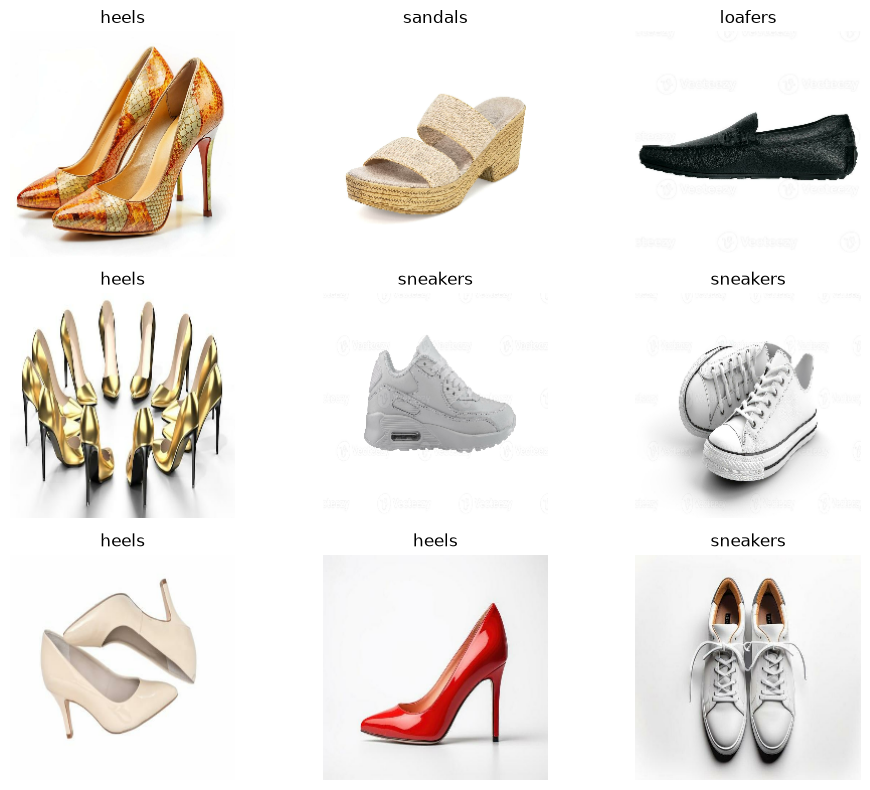

In [16]:
plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(np.argmax(labels[i]))])
        plt.axis("off")
plt.tight_layout()
plt.show()

## Step 6: Build the model (MobileNetV2 transfer learning)
* **MobileNetV2** is already trained on millions of images (ImageNet). We reuse it as a "feature extractor".
* We add our own small layer that outputs 5 shoe classes.
* **Data augmentation** (random flip / rotate / zoom) gives the model more variety.
* The first run downloads the MobileNetV2 weights (~14 MB), so you need internet once.

In [17]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")

base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base_model.trainable = False       # freeze pretrained layers for stage 1

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)                      # only active during training
x = layers.Rescaling(1./127.5, offset=-1)(x)       # scale pixels to [-1, 1] for MobileNetV2
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 6s 1us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Step 7: Train the model (stage 1)

In [18]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True)

history1 = model.fit(train_ds, validation_data=val_ds,
                     epochs=EPOCHS, callbacks=[early_stop])

Epoch 1/10


C:\Users\MOULIKA\anaconda3\envs\floodlens\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


13/13 ━━━━━━━━━━━━━━━━━━━━ 20s 851ms/step - accuracy: 0.3107 - loss: 1.6978 - val_accuracy: 0.4700 - val_loss: 1.3116
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 572ms/step - accuracy: 0.5947 - loss: 1.0348 - val_accuracy: 0.7200 - val_loss: 0.8652
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 625ms/step - accuracy: 0.7379 - loss: 0.7988 - val_accuracy: 0.8400 - val_loss: 0.6460
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 612ms/step - accuracy: 0.7767 - loss: 0.6276 - val_accuracy: 0.8600 - val_loss: 0.5495
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 649ms/step - accuracy: 0.8350 - loss: 0.5467 - val_accuracy: 0.8700 - val_loss: 0.4493
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 625ms/step - accuracy: 0.8592 - loss: 0.4662 - val_accuracy: 0.8600 - val_loss: 0.4575
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 624ms/step - accuracy: 0.8228 - loss: 0.4861 - val_accuracy: 0.8900 - val_loss: 0.3906
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 573ms/step - accuracy: 0.8762 - loss: 0.3942 - val_accuracy: 0.8900 - val

## Step 8: Fine-tune (stage 2, optional but improves accuracy)
We unfreeze the last 30 layers of MobileNetV2 and train them very gently.

In [19]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),   # very small learning rate
              loss="categorical_crossentropy", metrics=["accuracy"])

history2 = model.fit(train_ds, validation_data=val_ds,
                     epochs=FINE_TUNE_EPOCHS, callbacks=[early_stop])

Epoch 1/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 23s 858ms/step - accuracy: 0.7403 - loss: 0.7851 - val_accuracy: 0.9300 - val_loss: 0.3394
Epoch 2/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 676ms/step - accuracy: 0.7718 - loss: 0.7127 - val_accuracy: 0.9300 - val_loss: 0.3366
Epoch 3/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 721ms/step - accuracy: 0.7816 - loss: 0.6009 - val_accuracy: 0.9300 - val_loss: 0.3399
Epoch 4/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 680ms/step - accuracy: 0.8204 - loss: 0.5558 - val_accuracy: 0.9200 - val_loss: 0.3412
Epoch 5/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 679ms/step - accuracy: 0.8155 - loss: 0.5596 - val_accuracy: 0.9200 - val_loss: 0.3427


## Step 9: Check the results

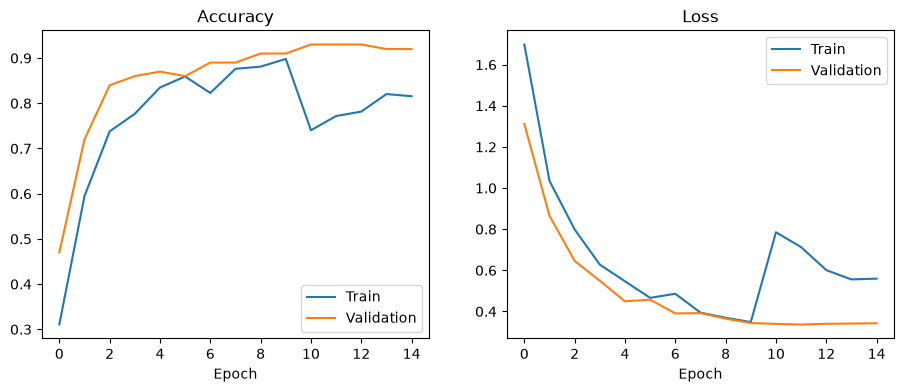

Final validation accuracy: 93.00%


In [20]:
acc  = history1.history["accuracy"]      + history2.history["accuracy"]
vacc = history1.history["val_accuracy"]  + history2.history["val_accuracy"]
loss = history1.history["loss"]          + history2.history["loss"]
vloss= history1.history["val_loss"]      + history2.history["val_loss"]

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label="Train"); plt.plot(vacc, label="Validation")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(loss, label="Train"); plt.plot(vloss, label="Validation")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
plt.show()

val_loss, val_acc = model.evaluate(val_ds, verbose=0)
print(f"Final validation accuracy: {val_acc*100:.2f}%")

              precision    recall  f1-score   support

       boots       0.95      0.95      0.95        20
       heels       1.00      0.82      0.90        22
     loafers       0.83      1.00      0.90        19
     sandals       0.95      0.90      0.92        20
    sneakers       0.95      1.00      0.97        19

    accuracy                           0.93       100
   macro avg       0.93      0.93      0.93       100
weighted avg       0.94      0.93      0.93       100



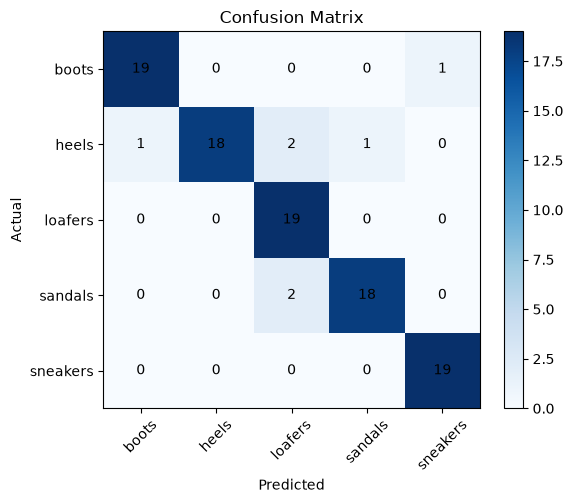

In [21]:
y_true, y_pred = [], []
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xticks(range(NUM_CLASSES), class_names, rotation=45)
plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.colorbar(); plt.tight_layout(); plt.show()

## Step 10: Save the model

In [22]:
model.save(MODEL_DIR / "shoe_classifier.keras")
with open(MODEL_DIR / "class_names.json", "w") as f:
    json.dump(class_names, f)
print("Saved:", MODEL_DIR / "shoe_classifier.keras")
print("Saved:", MODEL_DIR / "class_names.json")

Saved: C:\Users\MOULIKA\Downloads\ShoeTypeClassification\ShoeTypeClassification\model\shoe_classifier.keras
Saved: C:\Users\MOULIKA\Downloads\ShoeTypeClassification\ShoeTypeClassification\model\class_names.json


## Step 11: Test a prediction in the notebook
Change `test_path` to any shoe image on your laptop (for example one inside `sample_images`).

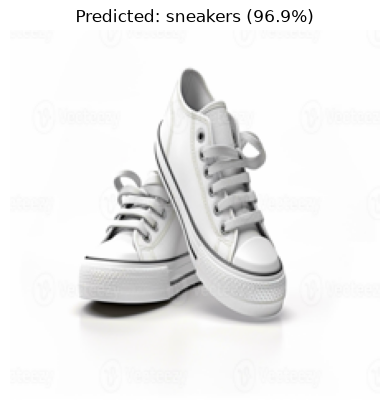

Real class: sneakers


In [23]:
# Picks a random validation image. Replace with your own path if you like, e.g.
# test_path = "sample_images/my_shoe.jpg"
test_path = random.choice(list(VAL_DIR.glob("*/*.jpg")))

img = Image.open(test_path).convert("RGB").resize(IMG_SIZE)
arr = np.expand_dims(np.array(img, dtype="float32"), axis=0)
probs = model.predict(arr, verbose=0)[0]
best = int(np.argmax(probs))

plt.imshow(img); plt.axis("off")
plt.title(f"Predicted: {class_names[best]} ({probs[best]*100:.1f}%)")
plt.show()
print("Real class:", test_path.parent.name)

## ✅ Done!
Now go back to the project folder and start the web app:

```
streamlit run app.py
```

In [4]:
!pip install icrawler

In [8]:
import tensorflow as tf
import numpy as np
import random

ImportError: DLL load failed while importing _pywrap_converter_api: An Application Control policy has blocked this file.

In [3]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [5]:
!pip install scikit-learn

In [3]:
import sys
!{sys.executable} -m pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.26.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.26.0-py3-none-any.whl (474 kB)
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   ---

In [1]:
print("TEST")

TEST


In [ ]:
import sys
!{sys.executable} -m pip install scikit-learn

In [11]:
import sys
!{sys.executable} -m pip install icrawler

  Using cached icrawler-0.6.10-py3-none-any.whl.metadata (6.2 kB)
  Using cached bs4-0.0.2-py2.py3-none-any.whl.metadata (411 bytes)
Using cached icrawler-0.6.10-py3-none-any.whl (36 kB)
Using cached bs4-0.0.2-py2.py3-none-any.whl (1.2 kB)
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   -- ------------------------------------- 0.3/4.0 MB ? eta -:--:--
   -- ------------------------------------- 0.3/4.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.5/4.0 MB 492.8 kB/s eta 0:00:08
   ----- ---------------------------------- 0.5/4.0 MB 492.8 kB/s eta 0:00:08
   ----- ---------------------------------- 0.5/4.0 